# Ejecución completa del análisis de Instacart

Este notebook recorre de principio a fin el flujo de análisis: carga de datos, exploración, filtros, indicadores, integración de tablas y visualizaciones. Ejecuta las celdas en orden con **Run All**.

> Los CSV incluidos en este repositorio son datos pequeños de ejemplo para demostrar el proceso. Los resultados no representan el conjunto completo de Instacart.

## 1. Preparar el entorno

Importamos las bibliotecas y configuramos el estilo de las gráficas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
print(f"pandas {pd.__version__} | numpy {np.__version__}")

pandas 3.1.0 | numpy 2.5.4


## 2. Encontrar y cargar los cinco archivos

Se buscan los archivos en las ubicaciones habituales al ejecutar el notebook desde `notebooks/` o desde la carpeta del proyecto. Si falta algún CSV, el error indica cuáles no se encontraron.

In [2]:
ARCHIVOS = [
    "instacart_orders.csv",
    "products.csv",
    "aisles.csv",
    "departments.csv",
    "order_products.csv",
]

rutas_candidatas = [
    Path("../data"),
    Path("data"),
    Path("instacart-analisis/data"),
]
DATA_DIR = next(
    (ruta.resolve() for ruta in rutas_candidatas
     if all((ruta / archivo).is_file() for archivo in ARCHIVOS)),
    None,
)

if DATA_DIR is None:
    faltantes = [
        archivo
        for archivo in ARCHIVOS
        if not any((ruta / archivo).is_file() for ruta in rutas_candidatas)
    ]
    raise FileNotFoundError(
        "No se encontraron todos los CSV. Revisa la carpeta data/ del proyecto. "
        f"Archivos faltantes: {', '.join(faltantes)}"
    )

print(f"Carpeta de datos: {DATA_DIR}")
print("Archivos encontrados:")
for archivo in ARCHIVOS:
    print(f"- {archivo}")

Carpeta de datos: D:\TRABAJOS SENA\FUNDAMENTOS EN PANDAS\instacart-analisis\data
Archivos encontrados:
- instacart_orders.csv
- products.csv
- aisles.csv
- departments.csv
- order_products.csv


In [3]:
orders = pd.read_csv(DATA_DIR / "instacart_orders.csv", sep=";", encoding="utf-8-sig")
products = pd.read_csv(DATA_DIR / "products.csv", sep=";", encoding="utf-8-sig")
aisles = pd.read_csv(DATA_DIR / "aisles.csv", sep=";", encoding="utf-8-sig")
departments = pd.read_csv(DATA_DIR / "departments.csv", sep=";", encoding="utf-8-sig")
order_products = pd.read_csv(DATA_DIR / "order_products.csv", sep=";", encoding="utf-8-sig")

dataframes = {
    "orders": orders,
    "products": products,
    "aisles": aisles,
    "departments": departments,
    "order_products": order_products,
}

print("Los cinco archivos se cargaron correctamente.")

Los cinco archivos se cargaron correctamente.


## 3. Explorar estructura y calidad

Revisamos dimensiones, primeras filas, tipos de datos y valores ausentes de cada tabla.

In [4]:
resumen_tablas = pd.DataFrame(
    [
        {
            "tabla": nombre,
            "filas": df.shape[0],
            "columnas": df.shape[1],
            "valores_ausentes": int(df.isna().sum().sum()),
        }
        for nombre, df in dataframes.items()
    ]
)
display(resumen_tablas)

for nombre, df in dataframes.items():
    print(f"\\n{nombre}: muestra de registros")
    display(df.head())

,tabla,filas,columnas,valores_ausentes
0,orders,4,7,3
1,products,3,4,0
2,aisles,3,2,0
3,departments,2,2,0
4,order_products,4,4,0


\norders: muestra de registros


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1,101,prior,1,0,10,NaN
1,2,102,train,1,1,14,NaN
2,3,101,prior,2,0,10,7.0
3,4,103,prior,1,2,9,NaN


\nproducts: muestra de registros


,product_id,product_name,aisle_id,department_id
0,1,Apple,1,1
1,2,Banana,2,1
2,3,Milk,3,2


...

,aisle_id,aisle
0,1,fruit
1,2,fruit
2,3,dairy


\ndepartments: muestra de registros


,department_id,department
0,1,produce
1,2,dairy


\norder_products: muestra de registros


,order_id,product_id,add_to_cart_order,reordered
0,1,1,1,0
1,1,2,2,1
2,2,3,1,0
3,3,1,1,1


In [5]:
for nombre, df in dataframes.items():
    print(f"\\n{nombre}: tipos de datos")
    display(df.dtypes.rename("tipo").to_frame())
    ausentes = df.isna().sum()
    ausentes = ausentes[ausentes > 0].rename("valores ausentes").to_frame()
    if ausentes.empty:
        print("Sin valores ausentes.")
    else:
        display(ausentes)

\norders: tipos de datos


,tipo
order_id,int64
user_id,int64
eval_set,str
order_number,int64
order_dow,int64
order_hour_of_day,int64
days_since_prior_order,float64


,valores ausentes
days_since_prior_order,3


\nproducts: tipos de datos


,tipo
product_id,int64
product_name,str
aisle_id,int64
department_id,int64


...

Sin valores ausentes.
\ndepartments: tipos de datos


,tipo
department_id,int64
department,str


Sin valores ausentes.
\norder_products: tipos de datos


,tipo
order_id,int64
product_id,int64
add_to_cart_order,int64
reordered,int64


Sin valores ausentes.


## 4. Aplicar filtros e indexación

Usamos `.loc` para consultar filas que cumplen condiciones de negocio. Cada resultado muestra su cantidad y una pequeña muestra.

In [6]:
filtros = {
    "Pedidos realizados a las 10": orders.loc[orders["order_hour_of_day"].eq(10)],
    "Productos del departamento 1": products.loc[products["department_id"].eq(1)],
    "Artículos marcados como recompra": order_products.loc[order_products["reordered"].eq(1)],
    "Artículos en primera posición del carrito": order_products.loc[
        order_products["add_to_cart_order"].eq(1)
    ],
}

for descripcion, resultado in filtros.items():
    print(f"{descripcion}: {len(resultado)} filas")
    display(resultado.head())

Pedidos realizados a las 10: 2 filas


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1,101,prior,1,0,10,NaN
2,3,101,prior,2,0,10,7.0


Productos del departamento 1: 2 filas


,product_id,product_name,aisle_id,department_id
0,1,Apple,1,1
1,2,Banana,2,1


Artículos marcados como recompra: 2 filas


,order_id,product_id,add_to_cart_order,reordered
1,1,2,2,1
3,3,1,1,1


Artículos en primera posición del carrito: 3 filas


,order_id,product_id,add_to_cart_order,reordered
0,1,1,1,0
2,2,3,1,0
3,3,1,1,1


## 5. Calcular indicadores descriptivos

Calculamos promedios y la proporción de recompras. Pandas omite valores ausentes al calcular la media; si una tabla está vacía, el resultado se conserva como `NaN`.

In [7]:
promedio_pedidos_cliente = (
    orders["order_number"].mean() if not orders.empty else np.nan
)
promedio_dias_entre_pedidos = (
    orders["days_since_prior_order"].mean() if not orders.empty else np.nan
)
cantidad_recompras = int(order_products["reordered"].eq(1).sum())
proporcion_recompras = (
    cantidad_recompras / len(order_products) if not order_products.empty else np.nan
)

indicadores = pd.DataFrame(
    {
        "Indicador": [
            "Filas de pedidos",
            "Productos en el catálogo",
            "Promedio de order_number",
            "Promedio de días entre pedidos",
            "Artículos marcados como recompra",
            "Proporción de artículos recompra",
        ],
        "Valor": [
            len(orders),
            len(products),
            promedio_pedidos_cliente,
            promedio_dias_entre_pedidos,
            cantidad_recompras,
            proporcion_recompras,
        ],
    }
)
display(indicadores)

,Indicador,Valor
0,Filas de pedidos,4.00
1,Productos en el catálogo,3.00
2,Promedio de order_number,1.25
3,Promedio de días entre pedidos,7.00
4,Artículos marcados como recompra,2.00
5,Proporción de artículos recompra,0.50


## 6. Integrar tablas y resumir compras

Relacionamos los artículos de cada pedido con el catálogo y el departamento para obtener conteos por producto y departamento.

In [8]:
articulos_detalle = order_products.merge(products, on="product_id", how="left")
articulos_detalle = articulos_detalle.merge(
    departments, on="department_id", how="left", suffixes=("", "_department")
)

productos_mas_comprados = (
    articulos_detalle.groupby("product_name", dropna=False)
    .size()
    .sort_values(ascending=False)
    .rename("unidades")
    .head(10)
    .reset_index()
)
departamentos_mas_comprados = (
    articulos_detalle.groupby("department", dropna=False)
    .size()
    .sort_values(ascending=False)
    .rename("unidades")
    .reset_index()
)

print("Productos con más artículos en los pedidos:")
display(productos_mas_comprados)
print("Artículos por departamento:")
display(departamentos_mas_comprados)

Productos con más artículos en los pedidos:


,product_name,unidades
0,Apple,2
1,Banana,1
2,Milk,1


Artículos por departamento:


,department,unidades
0,produce,3
1,dairy,1


## 7. Visualizar resultados

Las gráficas usan los datos cargados; si una tabla no tiene filas, se muestra un mensaje en vez de intentar graficar datos inexistentes.

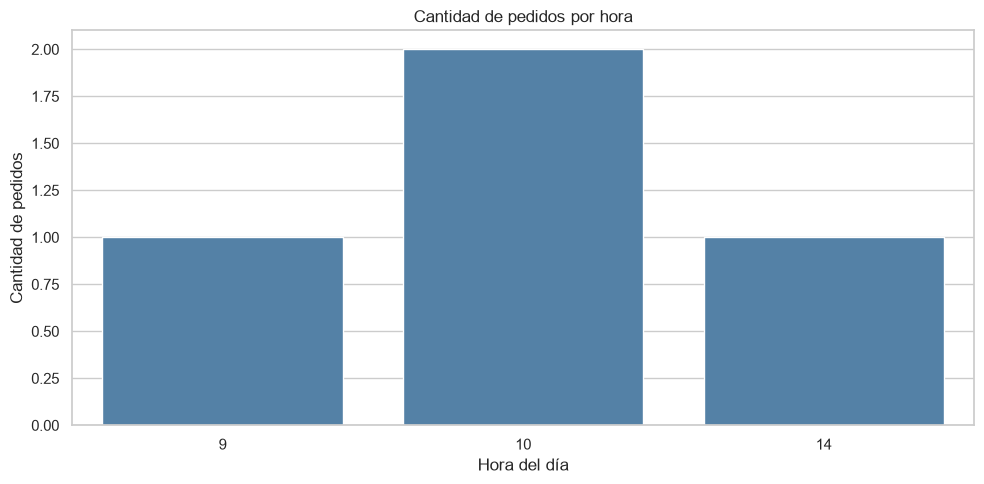

In [9]:
if orders["order_hour_of_day"].dropna().empty:
    print("No hay horas de pedidos para visualizar.")
else:
    sns.countplot(data=orders, x="order_hour_of_day", color="steelblue")
    plt.title("Cantidad de pedidos por hora")
    plt.xlabel("Hora del día")
    plt.ylabel("Cantidad de pedidos")
    plt.tight_layout()
    plt.show()

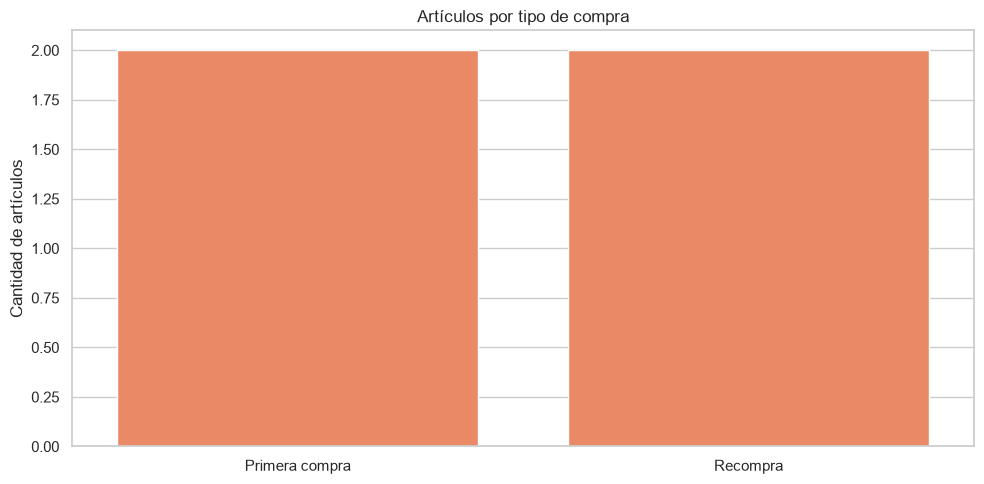

In [10]:
if order_products.empty:
    print("No hay artículos para visualizar.")
else:
    conteo_recompras = (
        order_products["reordered"]
        .map({0: "Primera compra", 1: "Recompra"})
        .fillna("Sin clasificar")
        .value_counts()
        .rename_axis("tipo de compra")
        .reset_index(name="artículos")
    )
    sns.barplot(data=conteo_recompras, x="tipo de compra", y="artículos", color="coral")
    plt.title("Artículos por tipo de compra")
    plt.xlabel("")
    plt.ylabel("Cantidad de artículos")
    plt.tight_layout()
    plt.show()

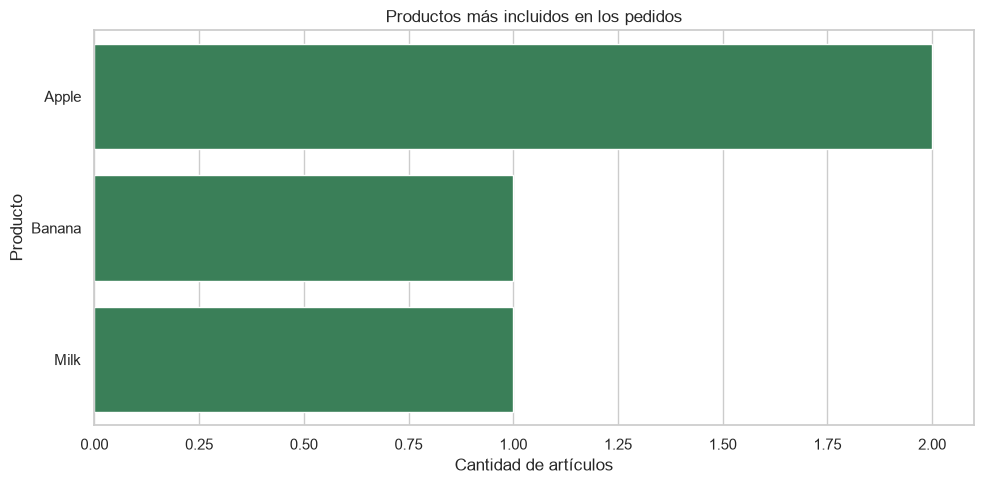

In [11]:
if productos_mas_comprados.empty:
    print("No hay productos para mostrar en el ranking.")
else:
    sns.barplot(
        data=productos_mas_comprados,
        x="unidades",
        y="product_name",
        color="seagreen",
    )
    plt.title("Productos más incluidos en los pedidos")
    plt.xlabel("Cantidad de artículos")
    plt.ylabel("Producto")
    plt.tight_layout()
    plt.show()

## 8. Conclusiones de esta ejecución

El resumen se genera a partir de los datos cargados, por lo que cambiar los CSV actualizará los valores.

In [12]:
print(f"Se analizaron {len(orders)} pedidos y {len(products)} productos.")
if pd.notna(promedio_pedidos_cliente):
    print(f"El promedio de order_number fue {promedio_pedidos_cliente:.2f}.")
else:
    print("No fue posible calcular el promedio de order_number.")
if pd.notna(proporcion_recompras):
    print(f"La proporción de artículos marcados como recompra fue {proporcion_recompras:.1%}.")
else:
    print("No hay artículos para calcular la proporción de recompras.")
if not productos_mas_comprados.empty:
    producto_lider = productos_mas_comprados.iloc[0]
    print(
        f"El producto con más registros en los pedidos fue "
        f"{producto_lider['product_name']} ({producto_lider['unidades']} artículos)."
    )
print("\nNota: estos resultados describen únicamente los CSV disponibles en este proyecto.")

Se analizaron 4 pedidos y 3 productos.
El promedio de order_number fue 1.25.
La proporción de artículos marcados como recompra fue 50.0%.
El producto con más registros en los pedidos fue Apple (2 artículos).

Nota: estos resultados describen únicamente los CSV disponibles en este proyecto.
